### 1. Carga y Preprocesamiento de Datos
En esta celda se importan las librerías necesarias (`numpy`, `matplotlib` y el conjunto de datos MNIST de `tensorflow`). Se cargan las imágenes de los dígitos de MNIST y se aplanan a vectores con un tamaño de muestra $N=60000$ y $p=784$ características ($28 \times 28$ píxeles).

Se calcula el vector de medias $\mu \in \mathbb{R}^{p \times 1}$ promediando sobre todas las muestras utilizando un vector columna de unos $\mathbf{1} \in \mathbb{R}^{N \times 1}$:

$$\mu = \frac{1}{N} X^T \mathbf{1}$$

In [1]:
import numpy as np
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
(X,Y), _=mnist.load_data()
X=X.reshape(-1,28*28)
N=X.shape[0]
ones=np.ones((N,1))
mu=X.T@ones/N


### 2. Cálculo de la Matriz de Covarianza
Aquí se centran los datos en una nueva matriz $X_c$ restando la media calculada a cada muestra (añadiendo adicionalmente un término de estabilidad numérica $\epsilon$ para evitar futuras indeterminaciones en píxeles sin varianza):

$$X_c = X - \mathbf{1}\mu^T + \epsilon$$

Posteriormente, se calcula la matriz de covarianza de las características $\Sigma \in \mathbb{R}^{p \times p}$ mediante el producto externo centrado:

$$\Sigma = \frac{1}{N} X_c^T X_c$$

In [2]:
ep=1e-10
X_c=X-ones@mu.T+ep

Cov=(1/N)*(X_c.T@X_c)

aux=np.diag(Cov)
Var=np.diag(aux)
print(Var.shape)

(784, 784)


### 3. Matriz de Correlación de Pearson
En esta celda se calcula el **Coeficiente de Correlación de Pearson** ($R \in \mathbb{R}^{p \times p}$). Para ello, se normalizan los valores de covarianza dividiendo cada elemento por el producto de las desviaciones estándar correspondientes:

$$R_{i,j} = \frac{\Sigma_{i,j}}{\sigma_i \sigma_j} = \frac{\Sigma_{i,j}}{\sqrt{\Sigma_{i,i} \Sigma_{j,j}}}$$

In [3]:
auxl=np.diag(Cov).reshape(-1,1)
den=auxl@auxl.T
print(den.shape)
R=Cov/np.sqrt(den)


(784, 784)


### 4. Visualización de la Matriz de Correlación
Finalmente, se utiliza `matplotlib` para generar un mapa de calor que visualiza la intensidad de las correlaciones entre los distintos píxeles de las imágenes de MNIST.

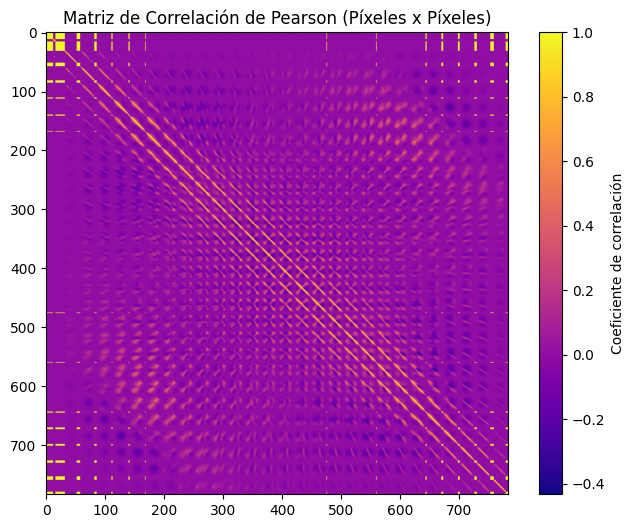

In [4]:
plt.figure(figsize=(8, 6))
plt.imshow(R, cmap='plasma')
plt.title('Matriz de Correlación de Pearson (Píxeles x Píxeles)')
plt.colorbar(label='Coeficiente de correlación')
plt.show()

### 5. Configuración del Tamaño de Muestras sin Centralizar en el Espacio del Kernel
Para evitar el desbordamiento de memoria derivado de una matriz de tamaño $N \times N$ ($60000 \times 60000$), trabajamos sobre un subconjunto representativo de $N_k = 5000$ muestras.
Definimos la matriz de Gram $K$ (similitud por producto interno) de manera directa sin aplicar transformaciones de centrado:

$$K = X_k X_k^T$$

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Recuperar el conjunto de datos X en caso de que no esté definido en el entorno actual
try:
    X
except NameError:
    from tensorflow.keras.datasets import mnist
    (X, Y), _ = mnist.load_data()
    X = X.reshape(-1, 28*28)

# Se seleccionan Nk = 5000 muestras para mantener la viabilidad de la memoria RAM al calcular matrices de tamaño Nk x Nk
Nk = 2000
X_k = X[:Nk].astype(np.float64)

# 1. Matriz de Gram (K) sin centralizar: Mide la similitud global cruda entre las muestras mediante el producto punto
K = X_k @ X_k.T

print("Dimensiones de la matriz de Gram sin centralizar:", K.shape)

Dimensiones de la matriz de Gram sin centralizar: (8000, 8000)


### 6. Covarianza, Varianza y Correlación sobre el Kernel sin Centralizar
En el espacio dual de características, la matriz de Gram sin centrar $K$ escalada por el factor $\frac{1}{N_k}$ representa la matriz de covarianza (sin centrar) estimada en el espacio del Kernel entre las muestras:

$$\Sigma_K = \frac{1}{N_k} K$$

Para obtener la matriz de correlación en este espacio $R_k \in \mathbb{R}^{N_k \times N_k}$, normalizamos esta matriz utilizando la raíz cuadrada de las varianzas (o momentos de segundo orden) en su diagonal:

$$(R_k)_{i,j} = \frac{(\Sigma_K)_{i,j}}{\sqrt{(\Sigma_K)_{i,i} (\Sigma_K)_{j,j}}}$$

In [6]:
# Cálculo de la matriz de covarianza en el espacio del kernel directamente sobre K (sin centralizar)
Cov_k = K / Nk

# Extraer la varianza de cada muestra en el espacio proyectado (elementos diagonales de la covarianza)
aux_k = np.diag(Cov_k)
Var_k = np.diag(aux_k)

# Factor epsilon para prevenir indeterminaciones matemáticas (divisiones por cero en muestras sin varianza)
ep = 1e-10
auxl_k = aux_k.reshape(-1, 1) + ep

# Producto externo de las desviaciones estándar para construir el denominador de la correlación
den_k = auxl_k @ auxl_k.T

# Matriz de Correlación R_k sin centralizar
R_k = Cov_k / np.sqrt(den_k)

print("Dimensiones de R_k (sin centralizar):", R_k.shape)

Dimensiones de R_k (sin centralizar): (8000, 8000)


### 7. Visualización del Kernel de Correlación
Se proyecta visualmente la matriz de correlación $R_k$ de tamaño $N_k \times N_k$. Esto permite mapear patrones estructurales y niveles de similitud cruzada entre las distintas imágenes del dataset de MNIST.

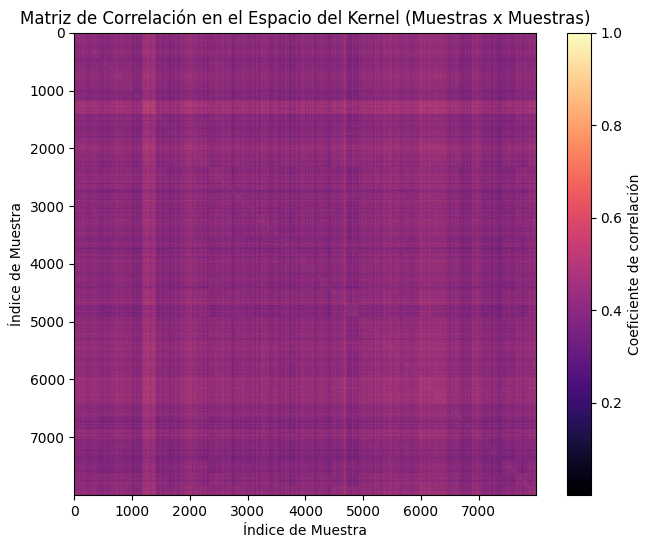

In [7]:
import matplotlib.pyplot as plt

# Generación del gráfico de calor para interpretar visualmente las correlaciones del Kernel entre muestras
plt.figure(figsize=(8, 6))
plt.imshow(R_k, cmap='magma')
plt.title('Matriz de Correlación en el Espacio del Kernel (Muestras x Muestras)')
plt.colorbar(label='Coeficiente de correlación')
plt.xlabel('Índice de Muestra')
plt.ylabel('Índice de Muestra')
plt.show()

### 8. Análisis: ¿Por qué al subir $N_k$ se "pierde" visualmente la diagonal?

La diagonal de cualquier matriz de correlación está compuesta por unos teóricos, ya que toda muestra tiene correlación perfecta consigo misma:

$$(R_k)_{i,i} = 1$$

Sin embargo, al visualizar el mapa de calor con valores grandes de $N_k$ (por ejemplo, pasando de $N_k=1000$ a $N_k=8000$), se observa que la línea diagonal se vuelve imperceptible o se difumina. Este fenómeno se debe a dos razones principales:

#### 1. Resolución Física y Densidad de Píxeles (Submuestreo en Pantalla)
* Cuando $N_k = 1000$, la matriz tiene $1000 \times 1000 = 1\times 10^6$ elementos. Cada celda de la matriz ocupa un área razonable en píxeles dentro de la figura de Matplotlib.
* Cuando aumentamos $N_k$ a $8000$, la matriz tiene $8000 \times 8000 = 64 \times 10^6$ elementos (64 millones de puntos de datos).
* Dado que el tamaño físico de la figura sigue siendo el mismo en pantalla (`figsize=(8,6)`), cada celda de la matriz debe ser submuestreada para caber en la resolución del monitor. Los algoritmos de renderizado y suavizado de imágenes (como la interpolación por defecto en `imshow`) promedian los píxeles adyacentes. Como la diagonal de valor $1$ es sumamente delgada (un solo elemento de ancho) frente a la inmensidad de los valores circundantes, el promedio visual termina atenuándola drásticamente.

#### 2. Correlaciones Estructurales Altas en MNIST
* Las imágenes de dígitos escritos a mano en MNIST comparten regiones espaciales idénticas (por ejemplo, los bordes negros y la zona central donde se dibuja el trazo).
* Al no centralizar la matriz de Gram $K$, no estamos removiendo la estructura común (la media global). Esto genera que muchas muestras distintas tengan un producto punto muy alto entre sí, provocando que los coeficientes fuera de la diagonal $(R_k)_{i,j}$ para $i \neq j$ sean muy cercanos a $1$ (por ejemplo, valores de $0.85$ a $0.95$).
* Al haber tan poco contraste de color entre la diagonal (que vale exactamente $1.0$) y el resto de la matriz (que tiene valores muy altos y mayoritarios en volumen), la diagonal pierde definición visual frente al color dominante del fondo.